# Timestral: checking Mistral's benchmark claims, then racing it against Prophet

**Context.** On 15 Oct 2026 Mistral released **Timestral**, a family of open time-series foundation models
(5M, 28M, 123M, 209M parameters; probabilistic, 21 quantiles; multivariate; past-only and known-future covariates;
context up to 32,768 steps; CPU inference). The [announcement](https://mistral.ai/news/timestral/) claims that
Timestral-209M **ranks first among pretrained / zero-shot models on GIFT-Eval, TIME and fev-bench, on all five
headline metrics**.

This notebook does two things:

1. **Audit the claim** from the *raw, public* result files that Mistral submitted to the benchmark maintainers
   (GIFT-Eval and fev-bench publish per-task results on GitHub). We recompute the leaderboards ourselves, check
   who Timestral is compared against, and test whether the margins are statistically meaningful.
2. **Compare Timestral with Meta's Prophet** (not on any of these leaderboards) using the *official* fev-bench
   harness: same tasks, same rolling windows, same metrics, same Seasonal-Naive normalisation. Prophet is then
   placed on the same leaderboard as the 41 published models.
3. A **bring-your-own-data** section to rerun the comparison on any pandas DataFrame (e.g. a client dataset).

**Requirements.** Python ≥ 3.10, internet access to `github.com` / `raw.githubusercontent.com` (result files) and
`huggingface.co` (Timestral weights + fev-bench datasets). A GPU is *not* needed. Part 1 runs in about a minute;
Part 2's runtime is driven by Prophet (one Stan fit per series per window) and is controlled by a budget parameter.

Everything is pinned to the commits that were current right after the release, so the numbers are reproducible.

## 0. Setup

In [1]:
# Run once (uncomment). Versions pinned to the commits used by Mistral's own fev-bench submission.
%pip install -q "fev @ git+https://github.com/autogluon/fev@f9e2c7d3152ed7d15c3b1c2877bb3ae7d977046f" \
                "timestral @ git+https://github.com/mistralai/timestral@a534bdbd244d64f3d9d743f46c7bf6fc330ed4ff" \
                prophet pandas matplotlib pyyaml joblib

In [2]:
import importlib.util
import json
import logging
import os
import subprocess
import time
import urllib.request
import warnings
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml

import fev

warnings.filterwarnings("ignore", category=FutureWarning)
for _name in ("cmdstanpy", "prophet", "prophet.plot"):
    logging.getLogger(_name).setLevel(logging.ERROR)
logging.getLogger("cmdstanpy").disabled = True
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

# ----------------------------------------------------------------------------------------------
# Configuration
# ----------------------------------------------------------------------------------------------
WORKDIR = Path(os.environ.get("TIMESTRAL_WORKDIR", "timestral_study")).resolve()
WORKDIR.mkdir(parents=True, exist_ok=True)

FEV_REPO, FEV_REF = "https://github.com/autogluon/fev", "f9e2c7d3152ed7d15c3b1c2877bb3ae7d977046f"
GIFT_REPO, GIFT_REF = "https://github.com/SalesforceAIResearch/gift-eval", "3c7be6deffb0046e1c08f9103db8bc84b3cf7ebd"

TIMESTRAL_SIZES = ["Timestral-5M", "Timestral-28M", "Timestral-123M", "Timestral-209M"]
TIMESTRAL_MODEL = "mistralai/Timestral-209M"   # model used in the head-to-head (Part 2-4)

# Part 2 budget. fev-bench has 100 tasks / ~235k series-windows; Prophet needs one fit per series-window.
# Tasks with more than MAX_FORECASTS_PER_TASK series-windows are skipped (≈50 tasks, ≈9k Prophet fits at 500).
MAX_FORECASTS_PER_TASK = int(os.environ.get("MAX_FORECASTS_PER_TASK", 500))
TASK_NAMES = os.environ.get("TIMESTRAL_TASKS")          # e.g. "epf_np,hospital_admissions_1W" to force a list
TASK_NAMES = TASK_NAMES.split(",") if TASK_NAMES else None
N_JOBS = int(os.environ.get("N_JOBS", -1))               # Prophet fits run in parallel across series
PROPHET_MAX_CONTEXT = 5_000                              # Prophet history cap (Stan cost grows with length)
PROPHET_SAMPLES = 300                                    # posterior predictive samples for Prophet quantiles
RERUN_TIMESTRAL = True                                   # rerun Timestral locally to check Mistral's numbers
SEED = 0

In [3]:
def fetch_repo_subset(repo_url: str, ref: str, paths: list[str], dest: Path) -> Path:
    """Shallow sparse checkout of a few folders of a GitHub repo (falls back to the zip archive)."""
    if dest.exists() and any(dest.iterdir()):
        return dest
    try:
        subprocess.run(["git", "clone", "-q", "--filter=blob:none", "--no-checkout", repo_url, str(dest)], check=True)
        subprocess.run(["git", "-C", str(dest), "sparse-checkout", "set", "--no-cone", *paths], check=True)
        subprocess.run(["git", "-C", str(dest), "checkout", "-q", ref], check=True)
    except Exception as e:  # no git: download the archive
        print(f"git unavailable ({e}); downloading zip archive")
        owner_repo = repo_url.removeprefix("https://github.com/")
        zpath = dest.with_suffix(".zip")
        urllib.request.urlretrieve(f"https://codeload.github.com/{owner_repo}/zip/{ref}", zpath)
        with zipfile.ZipFile(zpath) as z:
            root = z.namelist()[0].split("/")[0]
            for name in z.namelist():
                rel = name[len(root) + 1:]
                if rel and any(rel.startswith(p) for p in paths) and not name.endswith("/"):
                    out = dest / rel
                    out.parent.mkdir(parents=True, exist_ok=True)
                    out.write_bytes(z.read(name))
    return dest


fev_dir = fetch_repo_subset(FEV_REPO, FEV_REF, ["benchmarks/fev_bench/", "models/timestral/"], WORKDIR / "fev")
gift_dir = fetch_repo_subset(GIFT_REPO, GIFT_REF, ["results/"], WORKDIR / "gift-eval")
print("fev-bench result files :", len(list((fev_dir / "benchmarks/fev_bench/results").glob("*.csv"))))
print("GIFT-Eval result folders:", len(list((gift_dir / "results").iterdir())))

fev-bench result files : 41
GIFT-Eval result folders: 153


## 1. Decoding the claim

### 1.0 What is being measured

All three benchmarks score **zero-shot rolling-window forecasts** on many datasets and aggregate them
*relative to a Seasonal-Naive forecast* (repeat the last season), with a **geometric mean** across tasks:

| Metric | Definition (per series, horizon $H$, seasonality $m$) | Assesses |
|---|---|---|
| **MASE** | $\frac{\frac1H\sum_h \lvert y_{T+h}-\hat y_{T+h}\rvert}{\frac{1}{T-m}\sum_{t>m}\lvert y_t-y_{t-m}\rvert}$ | point forecast (median) |
| **WQL** ≈ CRPS | $\frac{\sum_{q}\sum_h 2\,\rho_q(y-\hat y^{(q)})}{\lvert Q\rvert\sum_h \lvert y\rvert}$, with pinball loss $\rho_q(u)=u(q-\mathbb 1_{u<0})$ | whole predictive distribution |
| **SQL** (fev) | same quantile loss, scaled like MASE (by the in-sample seasonal-naive error) | whole predictive distribution |

Aggregation: for each task, error ÷ Seasonal-Naive error; then geometric mean over tasks.
GIFT-Eval reports that geometric mean directly (lower is better, 1.0 = Seasonal Naive).
fev-bench reports a **skill score** $= 1 - \text{gmean}$ (higher is better, clipped to [0.01, 100]) and a
**win rate** (share of pairwise task-level wins against every other model).

**The claim to check:** Timestral-209M is #1 among *pretrained / zero-shot* models on
GIFT-Eval (MASE 0.658, CRPS/WQL 0.446), TIME (MASE 0.626, CRPS 0.522) and fev-bench
(SQL skill 50.39, MASE skill 39.49).

In [4]:
# Small self-contained implementation of the metrics, used later and for intuition.
def mase(y, yhat, y_hist, m):
    scale = np.nanmean(np.abs(y_hist[m:] - y_hist[:-m])) if len(y_hist) > m else np.nan
    return np.nanmean(np.abs(y - yhat)) / scale


def pinball(y, qhat, q):
    u = y - qhat
    return np.maximum(q * u, (q - 1) * u)


def wql(y, qhats: dict):
    return sum(2 * np.nansum(pinball(y, v, q)) for q, v in qhats.items()) / (len(qhats) * np.nansum(np.abs(y)))


def gmean(x):
    x = np.asarray(x, dtype=float)
    return float(np.exp(np.mean(np.log(x))))


# toy example: a seasonal series, a perfect-shape forecast vs seasonal naive
rng = np.random.default_rng(SEED)
t = np.arange(24 * 30)
y_all = 10 + 3 * np.sin(2 * np.pi * t / 24) + rng.normal(0, 0.5, t.size)
hist, fut = y_all[:-24], y_all[-24:]
snaive = hist[-24:]
print("MASE seasonal naive :", round(mase(fut, snaive, hist, 24), 3))
print("MASE true signal    :", round(mase(fut, 10 + 3 * np.sin(2 * np.pi * t[-24:] / 24), hist, 24), 3))

MASE seasonal naive : 1.029
MASE true signal    : 0.652


### 1.1 GIFT-Eval (Salesforce): 97 dataset × frequency × horizon configurations

Each submission folder holds `all_results.csv` (one row per configuration) and `config.json` (model type and a
self-declared **test-data-leakage** flag). We rebuild the leaderboard: per-config ratio to Seasonal Naive, geometric
mean over the 97 configs.

In [5]:
def load_gift_eval(results_dir: Path) -> pd.DataFrame:
    frames = []
    for d in sorted(results_dir.iterdir()):
        try:
            cfg = json.loads((d / "config.json").read_text())
            df = pd.read_csv(d / "all_results.csv")
        except Exception:
            continue
        df["model"] = d.name
        df["model_type"] = cfg.get("model_type")
        df["leakage"] = cfg.get("testdata_leakage")
        df["org"] = cfg.get("org")
        df["open_code"] = cfg.get("replication_code_available")
        frames.append(df)
    g = pd.concat(frames, ignore_index=True).rename(
        columns={"eval_metrics/MASE[0.5]": "MASE", "eval_metrics/mean_weighted_sum_quantile_loss": "CRPS"})
    g["term"] = g["dataset"].str.split("/").str[-1]
    complete = g.groupby("model")["dataset"].transform("nunique") == g["dataset"].nunique()
    g = g[complete]
    base = g[g.model == "Seasonal_Naive"].set_index("dataset")[["MASE", "CRPS"]]
    g = g.join(base, on="dataset", rsuffix="_sn")
    g["rel_MASE"] = g["MASE"] / g["MASE_sn"]
    g["rel_CRPS"] = g["CRPS"] / g["CRPS_sn"]
    return g


gift = load_gift_eval(gift_dir / "results")
gift_lb = (gift.groupby(["model", "model_type", "leakage", "org", "open_code"])
           .agg(MASE=("rel_MASE", gmean), CRPS=("rel_CRPS", gmean)).reset_index())
gift_lb["MASE_rank_all"] = gift_lb["MASE"].rank().astype(int)
gift_lb["CRPS_rank_all"] = gift_lb["CRPS"].rank().astype(int)

zs = gift_lb[gift_lb.model_type.isin(["pretrained", "zero-shot"]) & (gift_lb.leakage == "No")].copy()
zs["MASE_rank"] = zs["MASE"].rank().astype(int)
zs["CRPS_rank"] = zs["CRPS"].rank().astype(int)
print(f"{gift['dataset'].nunique()} configs, {len(gift_lb)} complete submissions, "
      f"{len(zs)} pretrained/zero-shot without declared leakage")
zs.sort_values("CRPS").head(15).round(4)

97 configs, 143 complete submissions, 75 pretrained/zero-shot without declared leakage


,model,model_type,leakage,org,open_code,MASE,CRPS,MASE_rank_all,CRPS_rank_all,MASE_rank,CRPS_rank
107,Timestral-209M,zero-shot,No,Mistral AI,Yes,0.6575,0.4460,11,8,2,1
106,Timestral-123M,zero-shot,No,Mistral AI,Yes,0.6589,0.4476,13,10,3,2
139,t0-gamma,pretrained,No,The Forecasting Company,Yes,0.6608,0.4520,16,13,4,3
73,STRIDE (+Chronos-2),pretrained,No,Google Cloud AI Research,No,0.6745,0.4544,34,17,12,4
56,Morpheus-2.0,pretrained,No,JP Morgan Chase,No,0.6459,0.4547,3,19,1,5
105,TimesFM-3,zero-shot,No,Google Research,Yes,0.6668,0.4557,24,22,7,6
44,Lingjiang2.0,zero-shot,No,Alibaba Cloud,No,0.6664,0.4565,23,25,6,7
18,EXAONE-Forecast,zero-shot,No,LG AI Research,No,0.6733,0.4600,32,28,10,8
64,QiYao-M,pretrained,No,"ECNU & Huawei Technologies Co., Ltd.",No,0.6711,0.4608,29,29,9,9
2,ChakraTS,pretrained,No,YHat Labs,No,0.6705,0.4609,27,30,8,10


**Reading.** The published numbers reproduce exactly (Timestral-209M: MASE 0.658, CRPS 0.446), and Timestral-209M
is #1 on CRPS among pretrained/zero-shot entries. Two nuances the press release does not mention:

* On **MASE** it is *not* #1 in that pool if you count every pretrained entry: check `Morpheus-2.0`
  (JP Morgan, pretrained, no declared leakage, *no public weights/code*), added to the repo the same day.
  Mistral's "#1 on all five metrics" holds against models with public code; it is not unconditional.
* Across **all** submission types, several *agentic* and *fine-tuned* systems score better; the claim is
  explicitly limited to pretrained / zero-shot models, which is the fair comparison for an off-the-shelf model.

In [6]:
def show_rank(df, models, cols=("MASE", "CRPS")):
    out = df[df.model.isin(models)].set_index("model")
    return out[[c for c in out.columns if any(c.startswith(k) for k in cols)]].round(4)


print("Best overall (any type):")
display(gift_lb.sort_values("CRPS").head(8)[["model", "model_type", "MASE", "CRPS"]].round(4))
show_rank(zs, ["Timestral-209M", "Timestral-123M", "Timestral-28M", "Timestral-5M", "Morpheus-2.0", "t0-gamma",
               "TimesFM-3", "Chronos-2", "Toto-2.0-2.5B"]).sort_values("CRPS")

Best overall (any type):


,model,model_type,MASE,CRPS
19,EXAONE-Forecast-Agent,agentic,0.6099,0.4185
119,TurkForecast-FM-Chronos2-LoRA-v1,fine-tuned,0.6582,0.4230
75,STRIDE_w_Synapse,agentic,0.6254,0.4233
82,TIMEHEDGE,agentic,0.6497,0.4438
59,PERSONA-AI-T4,agentic,0.6514,0.4445
41,LS-MoE,agentic,0.6500,0.4447
1,CastStar,agentic,0.6552,0.4453
107,Timestral-209M,zero-shot,0.6575,0.4460


,MASE,CRPS,MASE_rank_all,CRPS_rank_all,MASE_rank,CRPS_rank
model,,,,,,
Timestral-209M,0.6575,0.4460,11,8,2,1
Timestral-123M,0.6589,0.4476,13,10,3,2
t0-gamma,0.6608,0.4520,16,13,4,3
Morpheus-2.0,0.6459,0.4547,3,19,1,5
TimesFM-3,0.6668,0.4557,24,22,7,6
Timestral-28M,0.6780,0.4610,39,31,14,11
Toto-2.0-2.5B,0.6956,0.4759,57,54,22,17
Timestral-5M,0.7049,0.4789,71,59,32,21
Chronos-2,0.6978,0.4854,60,68,25,28


In [7]:
# Are the margins meaningful? Paired bootstrap over the 97 configurations of the gmean ratio Timestral / rival.
def paired_bootstrap(rel: pd.DataFrame, a: str, b: str, n=5000, seed=SEED):
    d = np.log(rel[a]) - np.log(rel[b])
    rs = np.random.default_rng(seed)
    boots = np.array([d.sample(frac=1, replace=True, random_state=rs.integers(1e9)).mean() for _ in range(n)])
    lo, hi = np.exp(np.percentile(boots, [2.5, 97.5]))
    return dict(rival=b, ratio=np.exp(d.mean()), ci_low=lo, ci_high=hi, a_wins=int((d < 0).sum()),
                b_wins=int((d > 0).sum()))


rows = []
for metric in ["rel_CRPS", "rel_MASE"]:
    piv = gift.pivot_table(index="dataset", columns="model", values=metric)
    for rival in ["Morpheus-2.0", "t0-gamma", "TimesFM-3", "Chronos-2", "Timestral-123M"]:
        if rival in piv:
            rows.append({"metric": metric[4:], **paired_bootstrap(piv, "Timestral-209M", rival)})
sig = pd.DataFrame(rows)
sig["significant"] = (sig.ci_high < 1) | (sig.ci_low > 1)
sig.round(4)

,metric,rival,ratio,ci_low,ci_high,a_wins,b_wins,significant
0,CRPS,Morpheus-2.0,0.9809,0.9293,1.0359,59,38,False
1,CRPS,t0-gamma,0.9868,0.9601,1.0190,65,32,False
2,CRPS,TimesFM-3,0.9788,0.9668,0.9913,72,25,True
3,CRPS,Chronos-2,0.9188,0.8993,0.9388,81,16,True
4,CRPS,Timestral-123M,0.9964,0.9917,1.0013,60,37,False
5,MASE,Morpheus-2.0,1.0180,0.9672,1.0765,60,37,False
6,MASE,t0-gamma,0.9950,0.9677,1.0296,59,38,False
7,MASE,TimesFM-3,0.9861,0.9752,0.9976,71,26,True
8,MASE,Chronos-2,0.9423,0.9269,0.9575,79,18,True
9,MASE,Timestral-123M,0.9979,0.9932,1.0028,60,37,False


`ratio` < 1 means Timestral-209M has lower error. A 95% interval that straddles 1 means the ranking between the two
models is **not** statistically distinguishable on this benchmark. At the pinned commit, the lead over TimesFM-3 and
Chronos-2 is significant (≈2% and ≈8% lower CRPS), while the gaps to t0-gamma and Morpheus-2.0 are within noise.

In [8]:
# Where does Timestral win? Breakdown by forecast horizon (term) and by domain.
focus = ["Timestral-209M", "Timestral-28M", "t0-gamma", "TimesFM-3", "Chronos-2", "Seasonal_Naive"]
sub = gift[gift.model.isin(focus)]
by_term = sub.pivot_table(index="model", columns="term", values="rel_CRPS", aggfunc=gmean).loc[focus]
by_dom = sub.pivot_table(index="model", columns="domain", values="rel_CRPS", aggfunc=gmean).loc[focus]
display(by_term.round(3))
by_dom.round(3)

term,long,medium,short
model,,,
Timestral-209M,0.423,0.421,0.465
Timestral-28M,0.442,0.437,0.478
t0-gamma,0.438,0.426,0.468
TimesFM-3,0.430,0.432,0.475
Chronos-2,0.472,0.471,0.496
Seasonal_Naive,1.000,1.000,1.000


domain,Econ/Fin,Energy,Healthcare,Nature,Sales,Transport,Web/CloudOps
model,,,,,,,
Timestral-209M,0.706,0.543,0.383,0.316,0.409,0.417,0.408
Timestral-28M,0.727,0.562,0.385,0.322,0.415,0.439,0.426
t0-gamma,0.704,0.532,0.408,0.327,0.410,0.425,0.426
TimesFM-3,0.717,0.567,0.400,0.326,0.411,0.402,0.418
Chronos-2,0.735,0.585,0.423,0.340,0.412,0.451,0.469
Seasonal_Naive,1.000,1.000,1.000,1.000,1.000,1.000,1.000


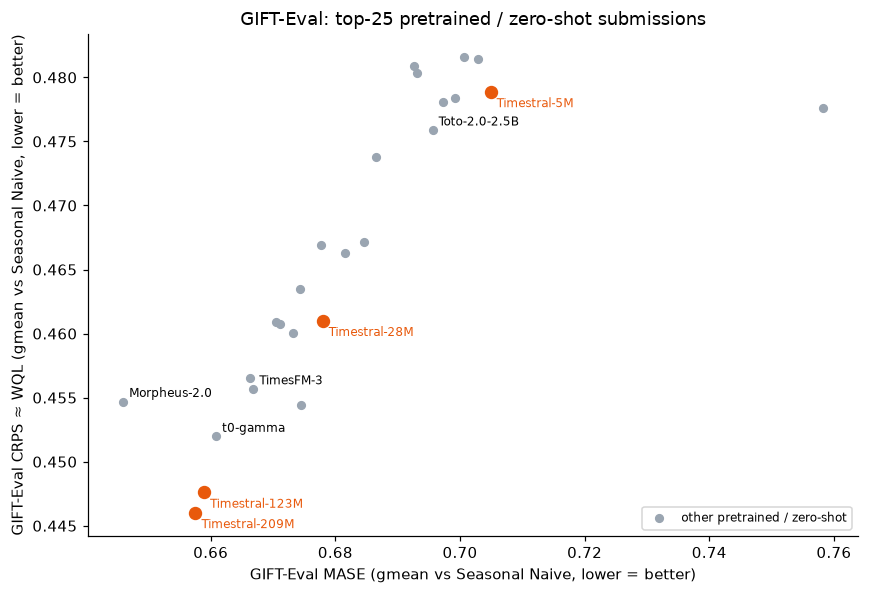

In [9]:
fig, ax = plt.subplots(figsize=(8, 5.5))
pool = zs.sort_values("CRPS").head(25)
ax.scatter(pool.MASE, pool.CRPS, s=25, color="#9aa5b1", label="other pretrained / zero-shot")
for _, r in pool.iterrows():
    if r.model.startswith("Timestral"):
        ax.scatter(r.MASE, r.CRPS, s=60, color="#e8590c", zorder=3)
        ax.annotate(r.model, (r.MASE, r.CRPS), fontsize=8, xytext=(4, -10), textcoords="offset points", color="#e8590c")
    elif r.model in ("Morpheus-2.0", "t0-gamma", "TimesFM-3", "Chronos-2", "Toto-2.0-2.5B"):
        ax.annotate(r.model, (r.MASE, r.CRPS), fontsize=8, xytext=(4, 3), textcoords="offset points")
ax.set_xlabel("GIFT-Eval MASE (gmean vs Seasonal Naive, lower = better)")
ax.set_ylabel("GIFT-Eval CRPS ≈ WQL (gmean vs Seasonal Naive, lower = better)")
ax.set_title("GIFT-Eval: top-25 pretrained / zero-shot submissions")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

### 1.2 fev-bench (AutoGluon): 100 tasks, 42 with dynamic covariates

The maintainers merged Mistral's per-task results (and the wrapper used to produce them) into the fev repository.
We recompute the leaderboard with `fev.leaderboard`, which applies the benchmark's own rules (Seasonal-Naive
baseline, clipping, leakage imputation with Chronos-Bolt), and add bootstrap confidence intervals.

In [10]:
FEV_RES = fev_dir / "benchmarks/fev_bench/results"
fev_all = pd.concat([pd.read_csv(f) for f in sorted(FEV_RES.glob("*.csv"))], ignore_index=True)
FEV_LB_KW = dict(missing_strategy="impute", baseline_model="Seasonal Naive", leakage_imputation_model="Chronos-Bolt")


def fev_leaderboard(summaries, metric, n_resamples=1000, **kw):
    lb = fev.leaderboard(summaries, metric_column=metric, n_resamples=n_resamples, **{**FEV_LB_KW, **kw})
    keep = [c for c in lb.columns if c.startswith(("win_rate", "skill_score"))] + ["median_e2e_time_s"]
    return lb[keep]


print(f"{fev_all.model_name.nunique()} models x {fev_all.task_name.nunique()} tasks")
lb_sql = fev_leaderboard(fev_all, "SQL")
lb_mase = fev_leaderboard(fev_all, "MASE")
lb_sql.head(12).round(4)

41 models x 100 tasks


,win_rate,win_rate_lower,win_rate_upper,skill_score,skill_score_lower,skill_score_upper,median_e2e_time_s
model_name,,,,,,,
Timestral-209M,0.8772,0.8487,0.9020,0.5039,0.4566,0.5504,3.5905
Timestral-123M,0.8685,0.8435,0.8915,0.5018,0.4559,0.5486,2.3207
TimeRSI,0.8480,0.8125,0.8830,0.5124,0.4664,0.5607,13483.6961
t0-gamma,0.8440,0.8162,0.8700,0.4942,0.4497,0.5412,16.2545
Timestral-28M,0.7918,0.7625,0.8198,0.4842,0.4384,0.5326,0.7368
timesfm-3,0.7855,0.7535,0.8163,0.4899,0.4445,0.5372,20.5133
ChakraTS,0.7820,0.7572,0.8093,0.4814,0.4378,0.5289,53.7500
Lingjiang2.0,0.7387,0.7112,0.7673,0.4702,0.4275,0.5175,54.4148
Chronos-2,0.7042,0.6740,0.7352,0.4728,0.4269,0.5209,2.6614


In [11]:
lb_mase.head(12).round(4)

,win_rate,win_rate_lower,win_rate_upper,skill_score,skill_score_lower,skill_score_upper,median_e2e_time_s
model_name,,,,,,,
Timestral-209M,0.8605,0.8292,0.8892,0.3949,0.3529,0.4355,3.5905
Timestral-123M,0.8497,0.8197,0.8770,0.3919,0.3505,0.4326,2.3207
TimeRSI,0.8382,0.7960,0.8772,0.4058,0.3629,0.4469,13483.6961
t0-gamma,0.8180,0.7865,0.8477,0.3799,0.3404,0.4194,16.2545
ChakraTS,0.7952,0.7720,0.8188,0.3693,0.3310,0.4102,53.7500
Timestral-28M,0.7700,0.7367,0.8005,0.3727,0.3331,0.4124,0.7368
timesfm-3,0.7700,0.7320,0.8053,0.3782,0.3376,0.4180,20.5133
Lingjiang2.0,0.7128,0.6815,0.7452,0.3538,0.3164,0.3938,54.4148
Chronos-2,0.6838,0.6490,0.7175,0.3550,0.3179,0.3932,2.6614


In [12]:
meta = fev_all.drop_duplicates("model_name").set_index("model_name")
med_train = fev_all.groupby("model_name").training_time_s.median()
print("Models that train per task (median training time > 0 s):")
med_train[med_train > 0].sort_values(ascending=False).round(0)

Models that train per task (median training time > 0 s):


model_name
TimeRSI     7399.0
DeepAR      5104.0
TFT         3848.0
PatchTST    2677.0
CatBoost     182.0
LightGBM      17.0
Name: training_time_s, dtype: float64

**Reading.** Mistral's published values reproduce (SQL skill 0.5039, MASE skill 0.3949). Timestral-209M has the
**highest win rate** of all 41 entries. On the *skill score*, `TimeRSI` is above it, but TimeRSI trains a model on
each task (≈2 h median training time per task), so it is not zero-shot: the "#1 among pretrained / zero-shot"
wording is accurate, and it matters.

In [13]:
# Covariates: Timestral advertises covariate support. Does its lead come from the 46 tasks with covariates?
task_meta = fev_all.drop_duplicates("task_name").set_index("task_name")
has_cov = (task_meta.known_dynamic_columns != "[]") | (task_meta.past_dynamic_columns != "[]")
is_mv = task_meta.target.astype(str).str.startswith("[")
rows = []
for label, tasks in {"all tasks": task_meta.index, "with covariates": has_cov[has_cov].index,
                     "no covariates": has_cov[~has_cov].index, "multivariate": is_mv[is_mv].index}.items():
    lb = fev.leaderboard(fev_all[fev_all.task_name.isin(tasks)], metric_column="SQL", **FEV_LB_KW)
    top = lb.sort_values("skill_score", ascending=False)
    zero_shot = top[~top.index.isin(med_train[med_train > 0].index)]          # drop per-task-trained models
    rival = zero_shot[~zero_shot.index.str.startswith("Timestral")]           # best non-Mistral zero-shot model
    rows.append({"subset": label, "n_tasks": len(tasks),
                 "Timestral-209M skill": lb.loc["Timestral-209M", "skill_score"],
                 "rank among zero-shot": int(zero_shot.index.get_loc("Timestral-209M")) + 1,
                 "best non-Mistral zero-shot": rival.index[0], "its skill": rival["skill_score"].iloc[0]})
pd.DataFrame(rows).round(4)

,subset,n_tasks,Timestral-209M skill,rank among zero-shot,best non-Mistral zero-shot,its skill
0,all tasks,100,0.5039,1,t0-gamma,0.4942
1,with covariates,42,0.5074,1,t0-gamma,0.4928
2,no covariates,58,0.5013,1,t0-gamma,0.4952
3,multivariate,35,0.5833,1,t0-gamma,0.5685


In [14]:
# Pairwise: probability that Timestral-209M beats a rival on a task, with bootstrap CI.
pw = fev.pairwise_comparison(fev_all, metric_column="SQL", missing_strategy="impute", baseline_model="Seasonal Naive",
                             leakage_imputation_model="Chronos-Bolt", n_resamples=1000,
                             included_models=["Timestral-209M", "t0-gamma", "timesfm-3", "Chronos-2", "TiRex-2",
                                              "Toto-2.0-2.5B", "AutoETS", "Seasonal Naive", "Chronos-Bolt"])
pw.loc["Timestral-209M"].round(3)

,win_rate,win_rate_lower,win_rate_upper,skill_score,skill_score_lower,skill_score_upper
model_2,,,,,,
Timestral-209M,0.50,0.50,0.50,0.000,0.000,0.000
t0-gamma,0.58,0.49,0.68,0.019,0.004,0.035
timesfm-3,0.75,0.66,0.83,0.027,0.014,0.042
Chronos-2,0.80,0.73,0.87,0.059,0.042,0.077
Toto-2.0-2.5B,0.77,0.69,0.85,0.107,0.075,0.139
TiRex-2,0.85,0.77,0.92,0.090,0.063,0.119
Chronos-Bolt,0.94,0.89,0.98,0.188,0.153,0.224
AutoETS,0.96,0.92,0.99,0.586,0.496,0.675
Seasonal Naive,1.00,1.00,1.00,0.504,0.457,0.550


`win_rate` = share of tasks where Timestral-209M beats the rival (ties = ½), `skill_score` = its relative error
reduction versus that rival; bounds are 95% bootstrap intervals over tasks. Against t0-gamma the win-rate interval
touches 0.5: on fev-bench the two are close to a coin flip task by task, even though Timestral wins on aggregate.

### 1.3 Size and speed

Mistral also claims every size sits on the accuracy/size Pareto front and that the small models punch above their
weight ("28M beats Chronos-2, about four times larger"). Parameter counts below are from model cards / papers
(TimesFM-3: 330M per third-party sources, unverified). Inference times are as *reported by each submitter on their own
hardware*, so they are indicative only.

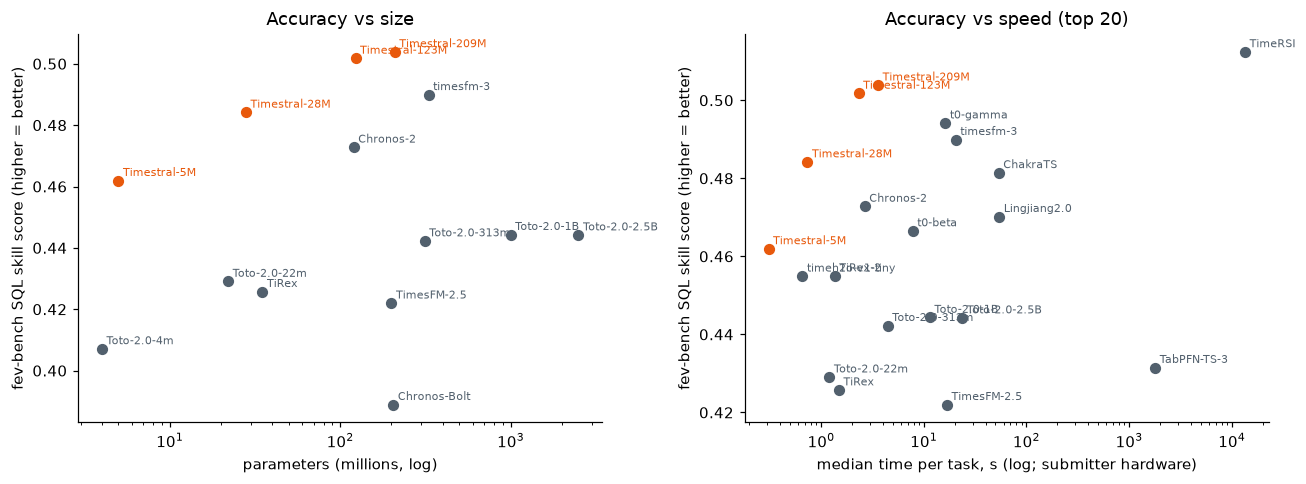

In [15]:
PARAMS_M = {"Timestral-5M": 5, "Timestral-28M": 28, "Timestral-123M": 123, "Timestral-209M": 209,
            "Chronos-2": 120, "Chronos-Bolt": 205, "TimesFM-2.5": 200, "timesfm-3": 330, "TiRex": 35,
            "Toto-2.0-4m": 4, "Toto-2.0-22m": 22, "Toto-2.0-313m": 313, "Toto-2.0-1B": 1000, "Toto-2.0-2.5B": 2500}
size_df = lb_sql.loc[lb_sql.index.intersection(list(PARAMS_M))].copy()
size_df["params_M"] = size_df.index.map(PARAMS_M)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, xcol, xlabel in [(axes[0], "params_M", "parameters (millions, log)"),
                         (axes[1], "median_e2e_time_s", "median time per task, s (log; submitter hardware)")]:
    src = size_df if xcol == "params_M" else lb_sql.head(20)
    for name, r in src.iterrows():
        c = "#e8590c" if name.startswith("Timestral") else "#52606d"
        ax.scatter(r[xcol], r["skill_score"], color=c, s=40)
        ax.annotate(name, (r[xcol], r["skill_score"]), fontsize=7, xytext=(3, 3), textcoords="offset points", color=c)
    ax.set_xscale("log")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("fev-bench SQL skill score (higher = better)")
axes[0].set_title("Accuracy vs size")
axes[1].set_title("Accuracy vs speed (top 20)")
plt.tight_layout()
plt.show()

### 1.4 TIME (98 tasks)

TIME's per-task results live only in its Hugging Face leaderboard space; no raw files in a Git repo at the pinned
date, so we cannot recompute them here. Mistral reports MASE 0.626 / CRPS 0.522 for Timestral-209M vs 0.640 / 0.536
for TimesFM-3. Treat these as **unverified** in this notebook.

### 1.5 Verdict on the claim (computed)

In [16]:
def verdict():
    t = "Timestral-209M"
    z = zs.set_index("model")
    lines = []
    for m in ["MASE", "CRPS"]:
        rank = int(z.loc[t, f"{m}_rank"])
        better = z[z[m] < z.loc[t, m]].index.tolist()
        lines.append(f"GIFT-Eval {m}: {z.loc[t, m]:.3f}, rank {rank}/{len(z)} among pretrained/zero-shot (no leakage)"
                     + (f"; ahead of it: {better}" if better else ""))
    for m, lb in [("SQL", lb_sql), ("MASE", lb_mase)]:
        r_skill = list(lb.sort_values("skill_score", ascending=False).index).index(t) + 1
        r_win = list(lb.sort_values("win_rate", ascending=False).index).index(t) + 1
        lines.append(f"fev-bench {m}: skill {lb.loc[t, 'skill_score']:.4f} (rank {r_skill}/{len(lb)} incl. per-task "
                     f"trained models), win rate {lb.loc[t, 'win_rate']:.3f} (rank {r_win})")
    n_sig = sig[sig.rival != "Timestral-123M"]
    lines.append("GIFT-Eval margins significant (95% paired bootstrap) vs: "
                 + ", ".join(f"{r.rival} [{r.metric}]" for r in n_sig.itertuples() if r.significant and r.ratio < 1))
    lines.append("GIFT-Eval margins NOT significant vs: "
                 + ", ".join(f"{r.rival} [{r.metric}]" for r in n_sig.itertuples() if not r.significant))
    return "\n".join("• " + s for s in lines)


print(verdict())

• GIFT-Eval MASE: 0.658, rank 2/75 among pretrained/zero-shot (no leakage); ahead of it: ['Morpheus-2.0']
• GIFT-Eval CRPS: 0.446, rank 1/75 among pretrained/zero-shot (no leakage)
• fev-bench SQL: skill 0.5039 (rank 2/41 incl. per-task trained models), win rate 0.877 (rank 1)
• fev-bench MASE: skill 0.3949 (rank 2/41 incl. per-task trained models), win rate 0.861 (rank 1)
• GIFT-Eval margins significant (95% paired bootstrap) vs: TimesFM-3 [CRPS], Chronos-2 [CRPS], TimesFM-3 [MASE], Chronos-2 [MASE]
• GIFT-Eval margins NOT significant vs: Morpheus-2.0 [CRPS], t0-gamma [CRPS], Morpheus-2.0 [MASE], t0-gamma [MASE]


## 2. Head-to-head: Timestral vs Prophet on fev-bench

Prophet is not on any of these leaderboards (it is not a foundation model and is slow to fit at scale). Published
evaluations generally find it **weaker than simple statistical baselines** on large benchmarks (e.g. Nixtla's
M3/M4/Tourism study, or arXiv 2407.16445 where default Prophet loses to AutoETS and often to Seasonal Naive).
Rather than rely on that, we measure it under exactly the same protocol as Timestral.

**Protocol.**
* Tasks: fev-bench tasks whose size (series × windows) fits the Prophet budget (`MAX_FORECASTS_PER_TASK`).
  Tasks are run *in full*, so the scores are directly comparable with the 41 published results.
* **Prophet (default)**: out-of-the-box `Prophet()`, quantiles from 300 posterior predictive samples, history capped
  at 5,000 points.
* **Prophet (+cov, ≥0)**: same, plus every numeric known-future covariate as a regressor, and forecasts clipped at 0
  for non-negative series (Timestral does the latter by default), i.e. a reasonably tuned "practitioner" Prophet.
* **Timestral**: the official fev wrapper written by Mistral (`models/timestral/model.py`), rerun locally to check
  that we reproduce their numbers.

In [ ]:
bench = fev.Benchmark.from_yaml(fev_dir / "benchmarks/fev_bench/tasks.yaml")
size = fev_all[fev_all.model_name == "Timestral-209M"].set_index("task_name")["num_forecasts"]
if TASK_NAMES:
    tasks = [t for t in bench.tasks if t.task_name in TASK_NAMES]
else:
    tasks = [t for t in bench.tasks if size.get(t.task_name, np.inf) <= MAX_FORECASTS_PER_TASK]
sel = pd.DataFrame({"task": [t.task_name for t in tasks], "horizon": [t.horizon for t in tasks],
                    "windows": [t.num_windows for t in tasks], "series x windows": [size.get(t.task_name) for t in tasks],
                    "covariates": [bool(t.known_dynamic_columns or t.past_dynamic_columns) for t in tasks]})
print(f"{len(tasks)} tasks selected, {int(sel['series x windows'].sum())} Prophet fits per Prophet variant, "
      f"{sel.covariates.sum()} tasks with covariates")
sel.head(10)

In [ ]:
def _prophet_one(hist: pd.DataFrame, fut: pd.DataFrame, quantile_levels, regressors, clip, n_samples, max_context):
    """Fit Prophet on one series and return (point, quantiles[H, Q])."""
    import logging as _lg
    _lg.getLogger("prophet.plot").setLevel(_lg.CRITICAL)
    from prophet import Prophet
    for name in ("cmdstanpy", "prophet"):
        lg = _lg.getLogger(name)
        lg.setLevel(_lg.ERROR)
        lg.propagate = False
        lg.disabled = True  # cmdstanpy attaches its own INFO handler lazily; disabling drops its records

    H = len(fut)
    hist = hist.tail(max_context)
    obs = hist.dropna(subset=["y"])
    if len(obs) < 3 or obs["y"].nunique() <= 1:  # degenerate history: carry last value
        last = float(obs["y"].iloc[-1]) if len(obs) else 0.0
        return np.full(H, last), np.full((H, len(quantile_levels)), last)
    regs = [r for r in regressors if hist[r].nunique(dropna=True) > 1]
    both = pd.concat([hist, fut], ignore_index=True)
    for r in regs:
        both[r] = both[r].astype(float).ffill().bfill().fillna(0.0)
    train = both.iloc[: len(hist)].dropna(subset=["y"])
    future = both.iloc[len(hist):][["ds"] + regs]
    m = Prophet(uncertainty_samples=0)
    for r in regs:
        m.add_regressor(r)
    m.fit(train[["ds", "y"] + regs])
    point = m.predict(future)["yhat"].to_numpy()
    m.uncertainty_samples = n_samples
    samples = m.predictive_samples(future)["yhat"]  # (H, n_samples)
    q = np.quantile(samples, quantile_levels, axis=1).T
    if clip and (obs["y"] >= 0).all():
        point, q = np.clip(point, 0, None), np.clip(q, 0, None)
    return point, np.sort(q, axis=1)


def _clean_ds(s: pd.Series) -> pd.Series:
    s = pd.to_datetime(s, errors="coerce")
    if getattr(s.dt, "tz", None) is not None:
        s = s.dt.tz_localize(None)
    return s


class ProphetModel(fev.ForecastingModel):
    """Prophet wrapper for fev tasks (one fit per series per window, parallel across series)."""

    model_name = "prophet_notebook"

    def __init__(self, use_covariates=False, clip_nonnegative=False, n_samples=PROPHET_SAMPLES,
                 max_context=PROPHET_MAX_CONTEXT, n_jobs=N_JOBS):
        super().__init__()
        self.use_covariates, self.clip = use_covariates, clip_nonnegative
        self.n_samples, self.max_context, self.n_jobs = n_samples, max_context, n_jobs

    def _fit_predict(self, task: fev.Task):
        from joblib import Parallel, delayed

        qs = list(task.quantile_levels)
        out = []
        for window in task.iter_windows():
            past, future, _ = fev.convert_input_data(window, adapter="nixtla", as_univariate=True)
            regs = []
            if self.use_covariates:  # numeric or boolean known-future covariates become Prophet regressors
                regs = [c for c in task.known_dynamic_columns
                        if c in future and (pd.api.types.is_numeric_dtype(past[c]) or pd.api.types.is_bool_dtype(past[c]))]
            past = past.assign(ds=_clean_ds(past["ds"]))
            future = future.assign(ds=_clean_ds(future["ds"]))
            for r in regs:
                past[r], future[r] = past[r].astype(float), future[r].astype(float)
            ids = pd.unique(past["unique_id"])
            gp, gf = dict(tuple(past.groupby("unique_id", sort=False))), dict(tuple(future.groupby("unique_id", sort=False)))
            with self._record_inference_time():
                res = Parallel(n_jobs=self.n_jobs, batch_size=4)(
                    delayed(_prophet_one)(gp[i][["ds", "y"] + regs].reset_index(drop=True),
                                          gf[i][["ds"] + regs].reset_index(drop=True),
                                          qs, regs, self.clip, self.n_samples, self.max_context) for i in ids)
            rows = {"predictions": np.concatenate([p for p, _ in res])}
            qmat = np.concatenate([q for _, q in res])
            rows.update({str(q): qmat[:, k] for k, q in enumerate(qs)})
            out.append(fev.utils.convert_forecast_df_to_predictions(
                pd.DataFrame(rows), horizon=task.horizon, quantile_levels=qs, target_columns=task.target_columns))
        return out


# Official Timestral wrapper, exactly as used for Mistral's fev-bench submission.
_spec = importlib.util.spec_from_file_location("fev_timestral", fev_dir / "models/timestral/model.py")
fev_timestral = importlib.util.module_from_spec(_spec)
_spec.loader.exec_module(fev_timestral)
timestral_model = fev_timestral.TimestralModel(model_path=TIMESTRAL_MODEL, device="auto")

In [ ]:
import re

RUN_DIR = WORKDIR / "runs"
RUN_DIR.mkdir(exist_ok=True)

MODELS = {
    "Prophet (default)": lambda: ProphetModel(use_covariates=False, clip_nonnegative=False),
    "Prophet (+cov, >=0)": lambda: ProphetModel(use_covariates=True, clip_nonnegative=True),
}
if RERUN_TIMESTRAL:
    MODELS[TIMESTRAL_MODEL.split("/")[-1] + " (local rerun)"] = lambda: timestral_model


def safe_filename(name):
    """Spaces -> '_', and replace characters Windows forbids in file names (e.g. '>' in 'Prophet (+cov, >=0)')."""
    return re.sub(r'[<>:"/\\|?*]', '_', name.replace(' ', '_'))


def run_model(display_name, factory, tasks):
    """Evaluate one model on the tasks; results are cached per task so the loop can be resumed."""
    model = factory()
    summaries = []
    for k, task in enumerate(tasks, 1):
        cache = RUN_DIR / f"{safe_filename(display_name)}__{safe_filename(task.task_name)}.json"
        if cache.exists():
            summaries.append(json.loads(cache.read_text()))
            continue
        t0 = time.time()
        try:
            preds = model.fit_predict(task)
            s = task.evaluation_summary(preds, model_name=display_name, training_time_s=model.training_time,
                                        inference_time_s=model.inference_time)
        except Exception as e:  # a failed task is scored as Seasonal Naive by fev (missing_strategy="impute")
            print(f"  ! {display_name} failed on {task.task_name}: {type(e).__name__}: {e}")
            continue
        cache.write_text(json.dumps(s, default=str))
        summaries.append(s)
        print(f"[{display_name}] {k}/{len(tasks)} {task.task_name}: SQL={s['SQL']:.3f} MASE={s['MASE']:.3f} "
              f"({time.time() - t0:.0f}s)")
    return pd.DataFrame(summaries)


local = {name: run_model(name, f, tasks) for name, f in MODELS.items()}

### 2.1 Reproduction check: our Timestral run vs Mistral's submitted numbers

In [ ]:
if RERUN_TIMESTRAL:
    ours = local[TIMESTRAL_MODEL.split("/")[-1] + " (local rerun)"].set_index("task_name")[["SQL", "MASE"]]
    theirs = fev_all[fev_all.model_name == TIMESTRAL_MODEL.split("/")[-1]].set_index("task_name")[["SQL", "MASE"]]
    chk = ours.join(theirs, rsuffix="_published", how="inner")
    chk["SQL_rel_diff_%"] = 100 * (chk.SQL / chk.SQL_published - 1)
    print(f"median |relative difference| on SQL: {chk['SQL_rel_diff_%'].abs().median():.3f}% over {len(chk)} tasks")
    display(chk.round(4).head(10))

### 2.2 Prophet placed on the official leaderboard (same tasks)

In [ ]:
def align_to_official(df):
    """Copy the official task-definition columns so fev pivots our rows onto the published tasks."""
    from fev.analysis import TASK_DEF_COLUMNS
    ref = fev_all.drop_duplicates("task_name").set_index("task_name")
    df = df.copy()
    for c in TASK_DEF_COLUMNS:
        if c in ref and c != "task_name":
            df[c] = df["task_name"].map(ref[c])
    return df


sel_names = [t.task_name for t in tasks]
prophet_rows = pd.concat([align_to_official(v) for k, v in local.items() if k.startswith("Prophet")], ignore_index=True)
combined = pd.concat([fev_all[fev_all.task_name.isin(sel_names)], prophet_rows], ignore_index=True)

h2h_sql = fev_leaderboard(combined, "SQL")
h2h_mase = fev_leaderboard(combined, "MASE")
focus_models = ["Timestral-209M", "Timestral-28M", "Timestral-5M", "timesfm-3", "Chronos-2", "AutoETS", "AutoARIMA",
                "Stat. Ensemble", "Seasonal Naive", "Prophet (default)", "Prophet (+cov, >=0)"]
tbl = pd.DataFrame({
    "rank (SQL skill)": h2h_sql["skill_score"].rank(ascending=False).astype(int),
    "SQL skill": h2h_sql["skill_score"], "SQL win rate": h2h_sql["win_rate"],
    "MASE skill": h2h_mase["skill_score"], "MASE win rate": h2h_mase["win_rate"],
    "median time / task (s)": h2h_sql["median_e2e_time_s"],
}).sort_values("SQL skill", ascending=False)
print(f"Leaderboard restricted to the {len(sel_names)} selected tasks, {len(tbl)} models")
tbl.loc[[m for m in focus_models if m in tbl.index]].round(3)

A skill score below 0 means **worse than Seasonal Naive** on (geometric) average.

In [ ]:
# Task-by-task: Timestral-209M vs best Prophet variant
pv = combined.pivot_table(index="task_name", columns="model_name", values="SQL")
pv = pv.div(pv["Seasonal Naive"], axis=0)  # per-task error relative to Seasonal Naive
best_prophet = "Prophet (+cov, >=0)" if h2h_sql.loc["Prophet (+cov, >=0)", "skill_score"] >= \
    h2h_sql.loc["Prophet (default)", "skill_score"] else "Prophet (default)"
duel = pv[["Timestral-209M", best_prophet, "AutoETS"]].dropna()
duel["Timestral / Prophet"] = duel["Timestral-209M"] / duel[best_prophet]
print(f"Timestral-209M beats {best_prophet} on {(duel['Timestral / Prophet'] < 1).sum()}/{len(duel)} tasks; "
      f"gmean error ratio = {gmean(duel['Timestral / Prophet']):.3f}")
print(f"{best_prophet} beats Seasonal Naive on {(duel[best_prophet] < 1).sum()}/{len(duel)} tasks; "
      f"Timestral-209M on {(duel['Timestral-209M'] < 1).sum()}/{len(duel)}")

fig, ax = plt.subplots(figsize=(7, 6))
lim = [min(duel.min().min(), 0.1) * 0.9, max(duel[["Timestral-209M", best_prophet]].max().max(), 2) * 1.1]
cov_flag = duel.index.map(lambda n: bool(has_cov.get(n, False)))
ax.scatter(duel[best_prophet], duel["Timestral-209M"], c=np.where(cov_flag, "#e8590c", "#3e4c59"), s=30)
ax.plot(lim, lim, color="grey", lw=1, ls="--")
ax.axvline(1, color="lightgrey", lw=1)
ax.axhline(1, color="lightgrey", lw=1)
ax.set_xscale("log"), ax.set_yscale("log"), ax.set_xlim(lim), ax.set_ylim(lim)
ax.set_xlabel(f"{best_prophet}: SQL / Seasonal Naive")
ax.set_ylabel("Timestral-209M: SQL / Seasonal Naive")
ax.set_title("Each dot = one fev-bench task (below diagonal: Timestral better)\norange = task with covariates")
plt.tight_layout()
plt.show()
duel.sort_values("Timestral / Prophet").round(3)

## 3. Look at the forecasts

Scores hide *how* the models differ. Below: the last evaluation window of one task, history, truth, and the
10%-90% bands of both models.

In [ ]:
def plot_window(task_name, n_series=3, window_idx=-1, history=None, prophet_kw=None):
    task = next(t for t in bench.tasks if t.task_name == task_name) if isinstance(task_name, str) else task_name
    window = task.get_window(window_idx % task.num_windows)
    past, future = window.get_input_data()
    truth = window.get_ground_truth()
    tgt = task.target_columns[0]  # multivariate tasks: plot the first target
    # Timestral on this window only (official wrapper internals), first n_series series
    tp = timestral_model._load_forecaster()
    table = task.load_full_dataset().data.table
    kinds = {c: fev_timestral.infer_column_kind(fev_timestral._flat_column(table, c)[0]) for c in task.dynamic_columns}
    items = timestral_model._window_items(task, past, future, kinds)[:n_series]
    tq = timestral_model._forecast_items(items, task.horizon)  # list of (V, H, Q)
    # Prophet on the same series (univariate view: ids cycle through targets)
    pp, pf, _ = fev.convert_input_data(window, adapter="nixtla", as_univariate=True)
    pp, pf = pp.assign(ds=_clean_ds(pp.ds)), pf.assign(ds=_clean_ds(pf.ds))
    regs = ([c for c in task.known_dynamic_columns if pd.api.types.is_numeric_dtype(pp[c])]
            if (prophet_kw or {}).get("use_covariates") else [])
    ids = pd.unique(pp.unique_id)[:: len(task.target_columns)][:n_series]
    levels = list(tp.quantile_levels)
    i10, i50, i90 = levels.index(0.1), levels.index(0.5), levels.index(0.9)
    fig, axes = plt.subplots(n_series, 1, figsize=(11, 2.8 * n_series), squeeze=False)
    for k, uid in enumerate(ids):
        ax = axes[k, 0]
        h = pp[pp.unique_id == uid]
        f = pf[pf.unique_id == uid]
        h_plot = h.tail(history or 4 * task.horizon)
        y_true = np.asarray(truth[k][tgt])
        ax.plot(h_plot.ds, h_plot.y, color="#3e4c59", lw=1, label="history")
        ax.plot(f.ds, y_true, color="black", lw=1.2, label="truth")
        q = tq[k][0]  # (H, Q) first variate
        ax.fill_between(f.ds, q[:, i10], q[:, i90], color="#e8590c", alpha=0.25)
        ax.plot(f.ds, q[:, i50], color="#e8590c", lw=1.3, label="Timestral median, 10-90%")
        pt, pq = _prophet_one(h[["ds", "y"] + regs].reset_index(drop=True), f[["ds"] + regs].reset_index(drop=True),
                              [0.1, 0.5, 0.9], regs, (prophet_kw or {}).get("clip_nonnegative", False),
                              PROPHET_SAMPLES, PROPHET_MAX_CONTEXT)
        ax.fill_between(f.ds, pq[:, 0], pq[:, 2], color="#1971c2", alpha=0.18)
        ax.plot(f.ds, pt, color="#1971c2", lw=1.3, label="Prophet yhat, 10-90%")
        ax.set_title(f"{task.task_name} | series {uid}", fontsize=9)
        if k == 0:
            ax.legend(fontsize=7, ncol=4, loc="upper left")
    plt.tight_layout()
    plt.show()


demo_task = next((n for n in ["hospital_admissions_1W", "epf_np", "ETT_1H"] if n in sel_names), sel_names[0])
plot_window(demo_task, n_series=3)

## 4. Bring your own data

`make_task` turns any long-format DataFrame (`id`, `timestamp`, `target`, optional covariates) into a fev `Task`
with rolling windows, so the exact same comparison runs on client data. Below it is demonstrated on a synthetic
retail-style panel (weekly seasonality, trend, and a **known-future promotion flag** that lifts sales), the typical
case where a covariate-aware model should shine.

In [ ]:
def make_task(df: pd.DataFrame, horizon: int, num_windows: int, seasonality: int, name: str,
              id_col="id", ts_col="timestamp", target="target", known=(), past=()) -> fev.Task:
    path = WORKDIR / f"{name}.parquet"
    df = df.sort_values([id_col, ts_col]).reset_index(drop=True)
    df[ts_col] = pd.to_datetime(df[ts_col])
    df.to_parquet(path, index=False)
    return fev.Task(dataset_path=str(path), id_column=id_col, timestamp_column=ts_col, target=target,
                    horizon=horizon, num_windows=num_windows, seasonality=seasonality,
                    known_dynamic_columns=list(known), past_dynamic_columns=list(past),
                    eval_metric="SQL", extra_metrics=["MASE", "WQL"], task_name=name,
                    quantile_levels=[0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9])


class SeasonalNaiveModel(fev.ForecastingModel):
    """Seasonal naive with Gaussian intervals (sigma of seasonal differences, widening per season), as in StatsForecast."""

    model_name = "seasonal_naive_notebook"

    def _fit_predict(self, task):
        from scipy.stats import norm
        m, H, qs = max(task.seasonality, 1), task.horizon, list(task.quantile_levels)
        out = []
        for window in task.iter_windows():
            past, _, _ = fev.convert_input_data(window, adapter="nixtla", as_univariate=True)
            rows = []
            for _, g in past.groupby("unique_id", sort=False):
                y = g["y"].ffill().fillna(0.0).to_numpy()
                mm = m if len(y) > m else 1
                last = y[-mm:]
                point = np.array([last[h % mm] for h in range(H)])
                sigma = np.nanstd(y[mm:] - y[:-mm]) if len(y) > mm + 1 else 0.0
                k = np.floor(np.arange(H) / mm) + 1
                quant = np.stack([point + norm.ppf(q) * sigma * np.sqrt(k) for q in qs], axis=1)
                rows.append((point, quant))
            pred = {"predictions": np.concatenate([p for p, _ in rows])}
            qm = np.concatenate([q for _, q in rows])
            pred.update({str(q): qm[:, j] for j, q in enumerate(qs)})
            out.append(fev.utils.convert_forecast_df_to_predictions(pd.DataFrame(pred), horizon=H,
                                                                    quantile_levels=qs,
                                                                    target_columns=task.target_columns))
        return out


def compare_on_task(task: fev.Task, models: dict | None = None) -> pd.DataFrame:
    models = models or {"Seasonal Naive": SeasonalNaiveModel(), "Prophet (default)": ProphetModel(),
                        "Prophet (+cov, >=0)": ProphetModel(use_covariates=True, clip_nonnegative=True),
                        TIMESTRAL_MODEL.split("/")[-1]: timestral_model}
    rows = []
    for name, mdl in models.items():
        t0 = time.time()
        s = task.evaluation_summary(mdl.fit_predict(task), model_name=name)
        rows.append({"model": name, "SQL": s["SQL"], "MASE": s["MASE"], "WQL": s["WQL"],
                     "seconds": time.time() - t0})
    res = pd.DataFrame(rows).set_index("model")
    for c in ["SQL", "MASE"]:
        res[f"{c} vs SNaive"] = res[c] / res.loc["Seasonal Naive", c]
    return res


# Synthetic retail panel: 40 stores x 2 years daily, weekly + yearly seasonality, trend, promotions (+35%).
rng = np.random.default_rng(SEED)
dates = pd.date_range("2024-01-01", periods=730, freq="D")
frames = []
for s in range(40):
    level = rng.uniform(50, 500)
    weekly = 1 + 0.25 * np.sin(2 * np.pi * (dates.dayofweek + rng.integers(7)) / 7)
    yearly = 1 + 0.15 * np.sin(2 * np.pi * dates.dayofyear / 365.25 + rng.uniform(0, 6))
    trend = 1 + rng.normal(0.0004, 0.0003) * np.arange(len(dates))
    promo = (rng.random(len(dates)) < 0.08).astype(float)
    y = level * weekly * yearly * trend * (1 + 0.35 * promo) * rng.lognormal(0, 0.08, len(dates))
    frames.append(pd.DataFrame({"id": f"store_{s:02d}", "timestamp": dates, "target": y.round(1), "promo": promo}))
retail = pd.concat(frames, ignore_index=True)

retail_task = make_task(retail, horizon=28, num_windows=4, seasonality=7, name="synthetic_retail", known=["promo"])
compare_on_task(retail_task).round(3)

In [ ]:
plot_window(retail_task, n_series=2, prophet_kw={"use_covariates": True, "clip_nonnegative": True})

### Using your own data

```python
df = pd.read_csv("my_sales.csv")            # columns: id, timestamp, target, [covariates...]
task = make_task(df, horizon=28, num_windows=5, seasonality=7, name="my_sales",
                 known=["promo", "holiday"],  # known in advance over the horizon
                 past=["footfall"])           # observed only up to the forecast date
compare_on_task(task)
```

## 5. Take-aways (fill in after running Part 2)

* **The claim holds, with qualifiers.** The published leaderboard numbers reproduce exactly from the raw files
  submitted to GIFT-Eval and fev-bench. "#1" is true among *pretrained / zero-shot* models: per-task-trained
  (TimeRSI on fev-bench), agentic and fine-tuned systems (GIFT-Eval) can score higher, and on GIFT-Eval MASE a
  closed model (Morpheus-2.0, JP Morgan) is ahead. Margins over the runner-ups are small; check the bootstrap table
  before calling it a clear win. TIME results could not be independently recomputed.
* **Covariates are not where the lead comes from.** On fev-bench, Timestral-209M's margin over the best non-Mistral
  zero-shot model (t0-gamma) is similar with and without covariates; it is largest on multivariate tasks.
* **Small models are the practical story.** Timestral-28M/123M sit close to 209M at a fraction of the cost and run
  on CPU in milliseconds per series, which matters more for most deployments than the last 0.2%.
* **Prophet:** see Part 2. Expect it to land around or below Seasonal Naive on average, with its
  best results on long, smooth, strongly seasonal series with holiday/regressor effects, and to be orders of
  magnitude slower (one Stan fit per series per forecast date) than a zero-shot forward pass.
* **Licence check before client use:** inference code is Apache-2.0, weights are under a *Modified MIT* licence
  (read the model card); fine-tuning goes through Mistral Forge.